In [1]:
import numpy as np
import scipy
from matplotlib import pyplot as plt
import itertools
import scipy.spatial

In [2]:
Args1 = ["a"]
Args2 = ["a", "b"]
Args3 = ["a", "b", "c"]

AttNone = []
AttBasic = [("a","b")]
AttChaine = [("a", "b"), ("b", "c")]
AttCycle = [("a","b"),("b","c"),("c","a")]
AttRec = [("a","b"),("b","a")]
AttAuto = [("a","a")]

In [3]:
def GraphToMatrix(Args, Graph):
  """
  Conversion d'un graphe d'argumentation en matrice d'adjacence
  Entrées : Args liste des arguments, Graph liste des attaques
  Sorties : M matrice d'adjacence
  """
  n = len(Args)
  Dict = {nom: i for i, nom in enumerate(Args)}
  M = np.zeros((n, n))
  for a, b in Graph:
      M[Dict[a]][Dict[b]] = 1
  return M

In [4]:
# Test de GraphToMatrix
print(GraphToMatrix(Args1,AttAuto))
print("")
print(GraphToMatrix(Args2,AttRec))
print("")
print(GraphToMatrix(Args3,AttChaine))
print("")
print(GraphToMatrix(Args3,AttCycle))

[[1.]]

[[0. 1.]
 [1. 0.]]

[[0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 0.]]

[[0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


Q1

In [5]:
def HCategorizer(M, W, Eps = 1e-8, Iterations = 10000):
  """
  Algorithme de calcul des scores h-categorizer
  Entrées : M matrice d'adjacence, W tableau des poids initiaux, Eps seuil de convergence, Iterations nombre max d'itérations
  Sorties : x tableau des scores calculés, NIter nombre d'itérations réelles
  """
  x = W.copy()
  NIter = Iterations
  for i in range(Iterations):
    v = W / (1 + x @ M)
    if np.max(np.abs(x - v)) > Eps:
      x = v
    else:
      NIter = i + 1
      break
  return x, NIter

In [6]:
# Test de HCategorizer

print(HCategorizer(GraphToMatrix(Args1,AttAuto),np.array([1])))
print(HCategorizer(GraphToMatrix(Args2,AttRec),np.array([1,1])))
print(HCategorizer(GraphToMatrix(Args3,AttChaine),np.array([1,1,1])))
print(HCategorizer(GraphToMatrix(Args3,AttCycle),np.array([1,1,1])))
print(HCategorizer(GraphToMatrix(Args3,AttChaine),np.array([0.8,0.6,0.5])))

(array([0.61803399]), 20)
(array([0.61803399, 0.61803399]), 20)
(array([1.        , 0.5       , 0.66666667]), 3)
(array([0.61803399, 0.61803399, 0.61803399]), 20)
(array([0.8       , 0.33333333, 0.375     ]), 3)


### Validation des résultats

Avec des poids initiaux tous égaux à 1, les valeurs obtenues correspondent aux calculs faits à la main, à 10⁻⁸ près.

**Vérifications à la main**
- Chaîne a → b → c : a n'est pas attaqué donc x_a = 1, puis x_b = 1 / (1 + 1) = 0,5, puis x_c = 1 / (1 + 0,5) = 2/3 ≈ 0,667. La sortie donne bien 1 ; 0,5 ; 0,66666667.
- Auto-attaque : x = 1 / (1 + x), soit x² + x − 1 = 0, dont la solution positive est (√5 − 1)/2 ≈ 0,61803399. C'est exactement la sortie.

**Interprétation**
- *Auto-attaque, a ↔ b et cycle* : ces trois graphes différents donnent tous 0,618. Dans chacun, chaque argument est attaqué par exactement un argument, et par symétrie tous les degrés sont égaux. On retombe donc à chaque fois sur la même équation x = 1 / (1 + x).
- *Réhabilitation dans la chaîne* : c remonte à 0,667 (au lieu de 0,5 s'il était attaqué par un argument non attaqué), car son attaquant b est lui-même affaibli par a. C'est le mécanisme de réhabilitation des sémantiques graduelles.

**Critère d'arrêt**
- La convergence n'est pas prouvée par nos tests : elle est garantie par un résultat théorique, puisque l'itération du h-categorizer converge vers un unique point fixe pour tout graphe fini (Amgoud et al., 2017).
- ε ne mesure pas l'erreur par rapport à la vraie valeur, mais l'écart entre deux itérations successives : on s'arrête quand max |x⁽ᵏ⁺¹⁾ − x⁽ᵏ⁾| ≤ ε.

Q2

In [7]:
def Echantillonage(M, N, Seed):
  """
  Fonction d'echantillonage
  Entrées : M Matrice d'adjacence, N Nombre de tirages, Seed graine aléatoire
  Sorties : W matrice des poids, X matrice des résultats
  """
  rng = np.random.default_rng(Seed)
  W = rng.random((N, M.shape[0])) # M.shape[0] -> nombre d’arguments
  X = HCategorizer(M, W)[0]
  return W, X

In [8]:
# Test echantillonage
W, X = Echantillonage(GraphToMatrix(Args3,AttChaine),100000,1)
print(W)
print(X)

[[0.51182162 0.9504637  0.14415961]
 [0.94864945 0.31183145 0.42332645]
 [0.82770259 0.40919914 0.54959369]
 ...
 [0.43457099 0.35044827 0.13398111]
 [0.86176482 0.32513544 0.59867548]
 [0.92360101 0.66663227 0.96521099]]
[[0.51182162 0.62868772 0.08851274]
 [0.94864945 0.1600244  0.36492892]
 [0.82770259 0.22388716 0.44905585]
 ...
 [0.43457099 0.24428786 0.10767694]
 [0.86176482 0.1746383  0.50966793]
 [0.92360101 0.34655433 0.71680063]]


In [9]:
%%time
# Temps de calcul : auto-attaque, N = 100 000, eps = 1e-8
M = GraphToMatrix(Args1, AttAuto)
W = np.random.default_rng(1).random((100000, 1))
X, NIter = HCategorizer(M, W, Eps=1e-8)
print("Nombre d'itérations :", NIter)

Nombre d'itérations : 20
CPU times: total: 15.6 ms
Wall time: 9.97 ms


In [10]:
%%time
# Temps de calcul : attaque symétrique a <-> b, N = 100 000, eps = 1e-8
M = GraphToMatrix(Args2, AttRec)
W = np.random.default_rng(1).random((100000, 2))
X, NIter = HCategorizer(M, W, Eps=1e-8)
print("Nombre d'itérations :", NIter)

Nombre d'itérations : 20
CPU times: total: 15.6 ms
Wall time: 15 ms


In [11]:
%%time
# Temps de calcul : attaque en chaîne, N = 100 000, eps = 1e-8
M = GraphToMatrix(Args3, AttChaine)
W = np.random.default_rng(1).random((100000, 3))
X, NIter = HCategorizer(M, W, Eps=1e-8)
print("Nombre d'itérations :", NIter)

Nombre d'itérations : 3
CPU times: total: 0 ns
Wall time: 4.75 ms


In [12]:
%%time
# Temps de calcul : cycle a -> b -> c -> a, N = 100 000, eps = 1e-8
M = GraphToMatrix(Args3, AttCycle)
W = np.random.default_rng(1).random((100000, 3))
X, NIter = HCategorizer(M, W, Eps=1e-8)
print("Nombre d'itérations :", NIter)

Nombre d'itérations : 20
CPU times: total: 15.6 ms
Wall time: 18.4 ms


Resultats pour N = 100 000 | ε = 1e-8 (une mesure par cellule ci-dessus)

| Graphe | Itérations | Temps (wall) |
|---|---|---|
| Auto-attaque | 20 | 10,0 ms |
| Attaque symétrique a ↔ b | 20 | 15,0 ms |
| Attaque en chaîne | 3 | 4,8 ms |
| Cycle a → b → c → a | 20 | 18,4 ms |

La chaîne est sans cycle : a ne bouge jamais, b est fixé dès la 1ʳᵉ itération, c dès la 2ᵉ, et la 3ᵉ ne fait que constater que plus rien ne bouge. Les valeurs deviennent exactes en un nombre fini d’itérations, égal à la longueur de la chaîne plus une (ici 2 + 1 = 3).
L’auto-attaque, a ↔ b et le cycle contiennent un cycle : les valeurs oscillent autour de la limite (1 ; 0,5 ; 0,667 ; 0,6…) et ne s’en rapprochent que progressivement. Il faut donc beaucoup plus d’itérations pour passer sous ε (20 au lieu de 3), d’où des temps plus longs.

In [13]:
def vis2D(X):
    """
    Visualisation 2D et calcul de l'enveloppe convexe
    Entrées : X matrice des résultats en 2D
    Sorties : hull enveloppe convexe des points
    """
    plt.scatter(X[:, 0], X[:, 1], s=1, alpha=.1)
    hull = scipy.spatial.ConvexHull(X)
    vertices = np.append(hull.vertices, hull.vertices[0])
    plt.plot(X[vertices, 0], X[vertices, 1], color="red", label="enveloppe convexe")

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel("deg A")
    plt.ylabel("deg B")
    return hull

Aire de l'enveloppe convexe :

 0.7478844797642135
Aire théorique (ln 2) : 0.6931471805599453
Sur-approximation : 0.07896923011365309


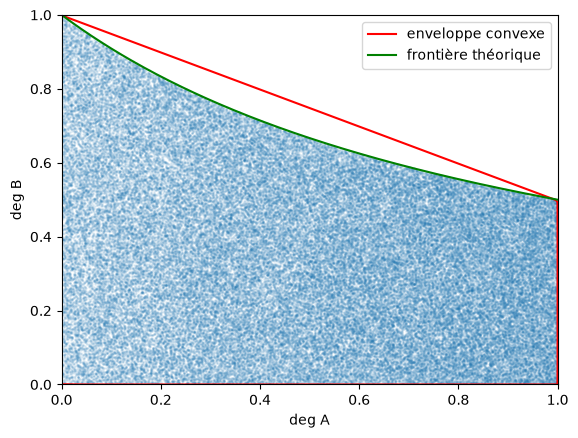

In [14]:
hull = vis2D(Echantillonage(GraphToMatrix(Args2,AttBasic),100000,1)[1])

t = np.linspace(0, 1, 200)
plt.plot(t,1/(1+t),color="green",label="frontière théorique")
plt.legend()

print("Aire de l'enveloppe convexe :", hull.volume)
print("Aire théorique (ln 2) :", np.log(2))
print("Sur-approximation :", hull.volume / np.log(2) - 1)

**Analyse : a → b (2D)**

- a n'est pas attaqué, donc x_a = w_a : il couvre tout [0, 1].
- b est attaqué par a : x_b = w_b / (1 + x_a) ≤ 1 / (1 + x_a). Les points restent sous la courbe verte, qui descend de 1 (a nul) à 0,5 (a = 1).
- La frontière est courbe, mais l'enveloppe convexe est faite de segments : elle relie (0, 1) à (1, 0,5) et englobe la zone vide entre la courbe et la droite.
- L'aire réelle se calcule à la main : ∫₀¹ dx / (1 + x) = ln 2 ≈ 0,693. L'enveloppe fait ≈ 0,748 (elle tend vers 0,75, l'aire du trapèze), soit environ 8 % de sur-approximation.

In [15]:
def vis3D(X,Angle = 50):
    """
    Visualisation 3D et calcul de l'enveloppe convexe
    Entrées : X matrice des résultats en 3D
    Sorties : hull enveloppe convexe des points
    """
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection="3d")
    ax.scatter(X[:5000, 0], X[:5000, 1], X[:5000, 2], s=1, alpha=1)
    hull = scipy.spatial.ConvexHull(X)
    ax.plot_trisurf(X[:, 0], X[:, 1], X[:, 2],triangles=hull.simplices,color="green", alpha=.2, linewidth=.2,edgecolor="black")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)
    ax.set_xlabel("deg A")
    ax.set_ylabel("deg B")
    ax.set_zlabel("deg C")

    ax.view_init(20,Angle)
    return hull

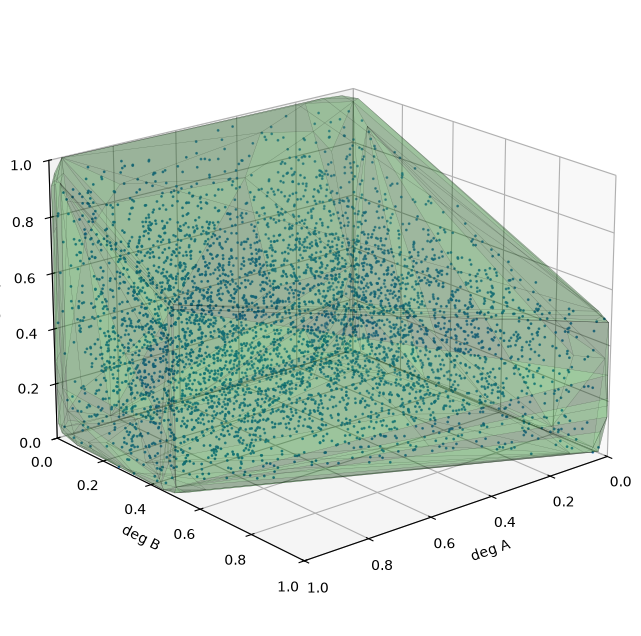

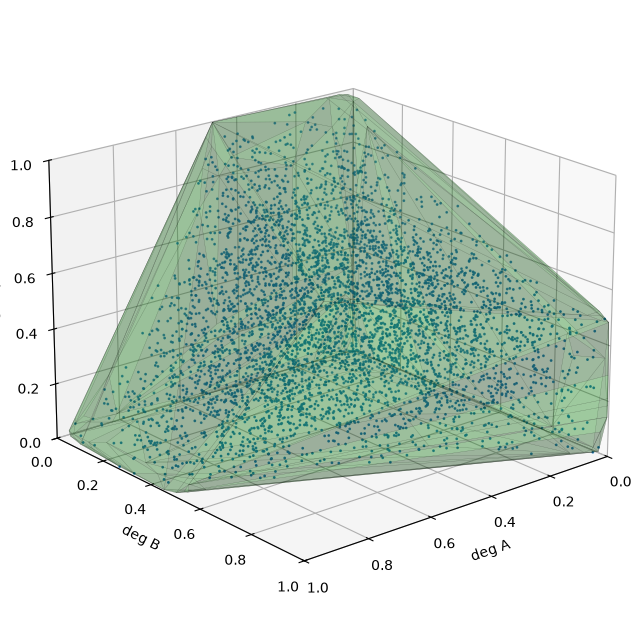

In [16]:
vis3D(Echantillonage(GraphToMatrix(Args3,AttChaine),100000,1)[1])
vis3D(Echantillonage(GraphToMatrix(Args3,AttCycle),100000,1)[1])

In [17]:
# Statistiques : chaîne et cycle (chiffres cités dans l'analyse)
W, X = Echantillonage(GraphToMatrix(Args3,AttChaine),100000,1)
faible = X[:, 1] < 0.1
print("Chaîne : moyenne de x_c quand x_b < 0.1 :", X[faible, 2].mean())
print("Chaîne : moyenne de w_c :", W[:, 2].mean())
print("Chaîne : corrélation (x_b, x_c) :", np.corrcoef(X[:, 1], X[:, 2])[0, 1])
print("Chaîne : corrélation (x_a, x_c) :", np.corrcoef(X[:, 0], X[:, 2])[0, 1])
print("Chaîne : part des tirages avec x_c > 0.6 :", np.mean(X[:, 2] > 0.6))
print("Chaîne : volume de l'enveloppe :", scipy.spatial.ConvexHull(X).volume)

X = Echantillonage(GraphToMatrix(Args3,AttCycle),100000,1)[1]
print("Cycle : moyennes des degrés :", X.mean(axis=0))
print("Cycle : volume de l'enveloppe :", scipy.spatial.ConvexHull(X).volume)

Chaîne : moyenne de x_c quand x_b < 0.1 : 0.4796967761856415
Chaîne : moyenne de w_c : 0.4992414602518671
Chaîne : corrélation (x_b, x_c) : -0.26049028424083914
Chaîne : corrélation (x_a, x_c) : 0.07384951962170908
Chaîne : part des tirages avec x_c > 0.6 : 0.19741
Chaîne : volume de l'enveloppe : 0.5886729840774773
Cycle : moyennes des degrés : [0.37216985 0.37139485 0.37220269]
Cycle : volume de l'enveloppe : 0.4700810397902698


**Analyse : chaîne et cycle (3D)**

*Chaîne a → b → c*
- a n'est pas attaqué ; b est contraint par a comme dans a → b.
- c est attaqué par b, mais b est lui-même affaibli par a : c'est la réhabilitation. Quand b est faible (x_b < 0,1), x_c vaut en moyenne 0,48, presque son poids initial moyen (0,5). x_c est négativement corrélé à x_b (−0,26) et légèrement positivement à x_a (+0,07) : un a fort affaiblit b, ce qui aide c.
- L'enveloppe a beaucoup de facettes : elle approxime des bords courbes par des triangles.

*Cycle a → b → c → a*
- Le graphe est symétrique, donc les trois degrés ont la même moyenne (≈ 0,37).
- Aucun argument n'est libre, donc l'espace est plus petit que pour la chaîne : volume de l'enveloppe ≈ 0,47 contre ≈ 0,59.

In [18]:
def visnD(X):
    """
    Visualisation nD et calcul des enveloppes convexes par paires de dimensions
    Entrées : X matrice des résultats en nD
    Sorties : hulls liste des enveloppes convexes, une par paire d'arguments
    """
    n = X.shape[1]
    pairs = list(itertools.combinations(range(n), 2))

    fig, axes = plt.subplots(1, len(pairs), figsize=(4 * len(pairs), 4))

    hulls = []
    for k, (i, j) in enumerate(pairs):
        ax = axes[k]
        pts = X[:5000, [i, j]]
        ax.scatter(pts[:, 0], pts[:, 1], s=1, alpha=1)

        hull = scipy.spatial.ConvexHull(X[:, [i, j]])
        hulls.append(hull)

        vertices = np.append(hull.vertices, hull.vertices[0])
        ax.plot(X[vertices, i], X[vertices, j], color="red", label="enveloppe convexe")

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel("deg " + chr(ord('A') + i))
        ax.set_ylabel("deg " + chr(ord('A') + j))

    fig.suptitle("Projections par paires")
    return hulls

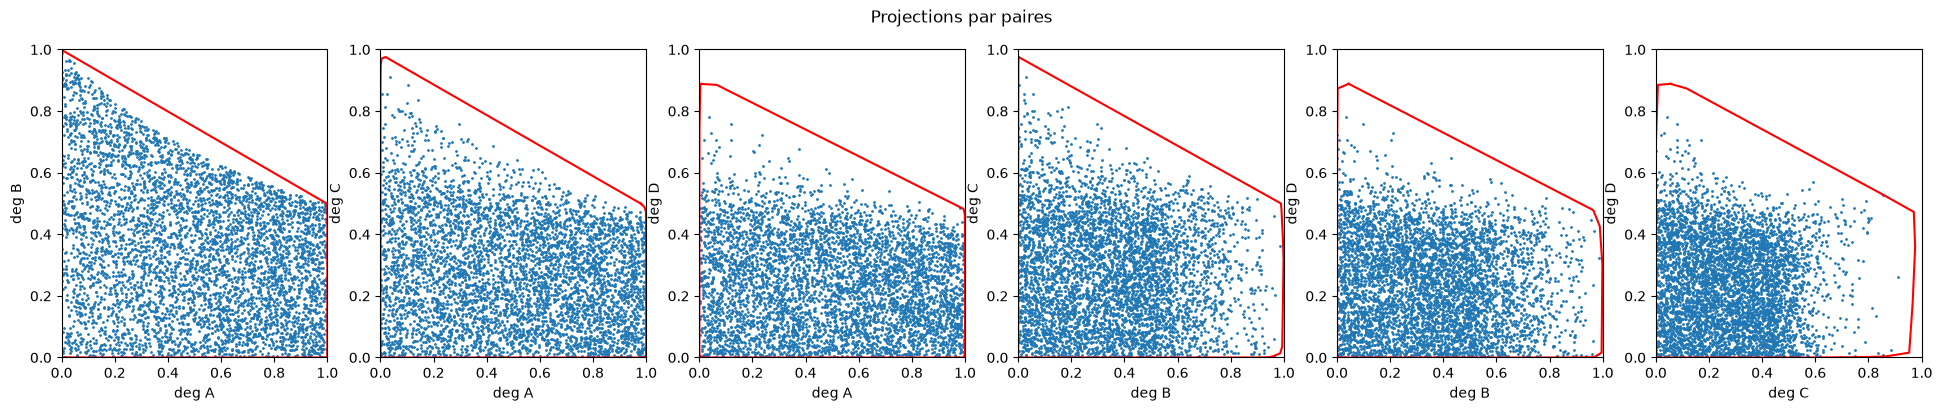

In [19]:
# Test visND

Args4 = ["a", "b", "c", "d"]
Att4 = [("a","b"),("a","c"),("a","d"),
        ("b","c"),("b","d"),
        ("c","d")]

visnD(Echantillonage(GraphToMatrix(Args4,Att4),100000,1)[1])

In [20]:
# Statistiques : graphe à 4 arguments (chiffres cités dans l'analyse)
X = Echantillonage(GraphToMatrix(Args4,Att4),100000,1)[1]
print("Moyennes des degrés (a, b, c, d) :", X.mean(axis=0))
print("Maximum de x_d :", X[:, 3].max())
print("Part des tirages avec x_d < 0.2 :", np.mean(X[:, 3] < 0.2))
print("Part des tirages avec x_d < 0.4 :", np.mean(X[:, 3] < 0.4))
print("Aire de l'enveloppe de la projection (c, d) :", scipy.spatial.ConvexHull(X[:, [2, 3]]).volume)

Moyennes des degrés (a, b, c, d) : [0.49914744 0.34770969 0.27808189 0.24045538]
Maximum de x_d : 0.8884919188989535
Part des tirages avec x_d < 0.2 : 0.42603
Part des tirages avec x_d < 0.4 : 0.84581
Aire de l'enveloppe de la projection (c, d) : 0.6748056491088976


**Analyse : graphe à 4 arguments (projections)**

Ici a attaque b, c, d ; b attaque c, d ; c attaque d.

- Plus un argument est attaqué, plus il est bas : moyennes a ≈ 0,50, b ≈ 0,35, c ≈ 0,28, d ≈ 0,24. d ne dépasse jamais 0,89, et 43 % des tirages donnent x_d < 0,2.
- La projection (a, b) est exactement la figure a → b, car a et b ne dépendent pas de c et d.
- Les projections avec c ou d sont écrasées vers le bas. Par exemple, le nuage (c, d) est surtout dans [0 ; 0,5] × [0 ; 0,4], alors que son enveloppe a une aire ≈ 0,67.
- Les projections ne sont que des « ombres » de l'espace 4D : on voit les contraintes deux à deux, pas tout l'espace.

In [21]:
def vis(X):
  # juste pour que ce soit propre
  if(X.shape[1]==2):
    vis2D(X)
  elif(X.shape[1]==3):
    vis3D(X)
  else:
    visnD(X)

In [22]:
# Volume de l'enveloppe convexe pour chaque graphe (fraction de l'hypercube [0, 1]^n)
Graphes = [("sans attaque", Args2, AttNone), ("a -> b", Args2, AttBasic), ("a <-> b", Args2, AttRec),
           ("chaîne", Args3, AttChaine), ("cycle", Args3, AttCycle), ("4 arguments", Args4, Att4)]
for nom, Args, Att in Graphes:
  X = Echantillonage(GraphToMatrix(Args, Att), 100000, 1)[1]
  print(f"{nom:12s} volume de l'enveloppe = {scipy.spatial.ConvexHull(X).volume:.3f}")
print("aire réelle de a -> b (ln 2) =", np.log(2))

sans attaque volume de l'enveloppe = 1.000
a -> b       volume de l'enveloppe = 0.748
a <-> b      volume de l'enveloppe = 0.616
chaîne       volume de l'enveloppe = 0.589
cycle        volume de l'enveloppe = 0.470


4 arguments  volume de l'enveloppe = 0.246


aire réelle de a -> b (ln 2) = 0.6931471805599453


**Analyse générale des enveloppes**

| Graphe | Dimension | Volume de l'enveloppe |
|---|---|---|
| sans attaque | 2 | 1 |
| a → b | 2 | 0,748 |
| a ↔ b | 2 | 0,616 |
| chaîne | 3 | 0,589 |
| cycle | 3 | 0,470 |
| 4 arguments | 4 | 0,246 |

- Chaque attaque impose une contrainte du type x_b ≤ 1/(1 + x_a), qui enlève un morceau de l'hypercube.
- Attention, les volumes ne sont comparables qu'à dimension égale. Une même contrainte n'a pas le même effet en 2D, 3D ou 4D, et les contraintes se cumulent quand la dimension augmente. Comparer « 1 sans attaque » à « 0,25 pour 4 arguments » mélangerait donc l'effet des attaques et celui de la dimension. Les comparaisons justes sont :
  - en 2D : a → b (0,748) contre a ↔ b (0,616), où l'attaque en retour réduit encore l'espace ;
  - en 3D : chaîne (0,589) contre cycle (0,470), car dans le cycle aucun argument n'est libre.
- En 2D et en 3D on voit l'espace directement ; au-delà, il ne reste que des projections.
- L'enveloppe convexe sur-approxime l'espace dès que la frontière est courbe. On l'a chiffré sur a → b (≈ 8 %, avec ln 2 calculé à la main) ; pour les autres graphes, on le voit sur les figures : il y a des zones vides entre les points et l'enveloppe.

In [23]:
def HeatMap(X):
    """
    """
    n = X.shape[1]
    pairs = list(itertools.combinations(range(n), 2))

    fig, axes = plt.subplots(1, len(pairs), figsize=(4 * len(pairs), 4),squeeze=False)

    hulls = []
    for k, (i, j) in enumerate(pairs):
        ax = axes[0, k]
        hist = ax.hist2d(X[:, i], X[:, j], bins=50, range=[[0, 1], [0, 1]],cmap="inferno", density=True)
        fig.colorbar(hist[3], ax=ax)
        hull = scipy.spatial.ConvexHull(X[:, [i, j]])
        hulls.append(hull)

        vertices = np.append(hull.vertices, hull.vertices[0])
        ax.plot(X[vertices, i], X[vertices, j], color="red", label="enveloppe convexe")

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_xlabel("deg " + chr(ord('A') + i))
        ax.set_ylabel("deg " + chr(ord('A') + j))

    fig.suptitle("Projections par paires")
    return hulls

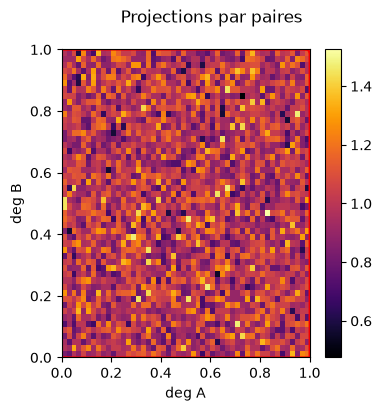

In [24]:
# Heatmap : sans attaque (référence, x = w)
HeatMap(Echantillonage(GraphToMatrix(Args2,AttNone),100000,1)[1])

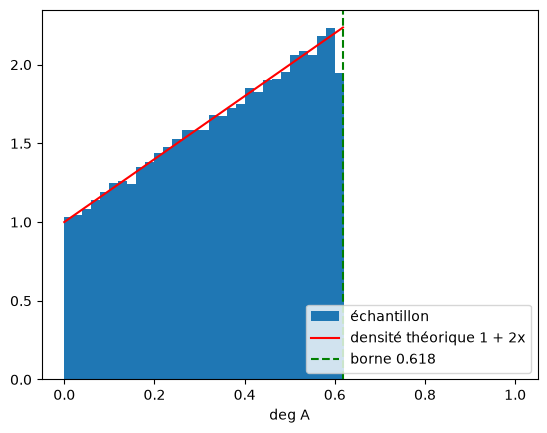

In [25]:
# Histogramme 1D : auto-attaque
X = Echantillonage(GraphToMatrix(Args1,AttAuto),100000,1)[1]
phi = (np.sqrt(5) - 1) / 2
plt.hist(X[:, 0], bins=50, range=(0, 1), density=True, label="échantillon")
t = np.linspace(0, phi, 200)
# x(1 + x) = w, donc densité de x = 1 + 2x sur [0, 0.618] (intégrale = 1)
plt.plot(t, 1 + 2 * t, color="red", label="densité théorique 1 + 2x")
plt.axvline(phi, color="green", linestyle="--", label="borne 0.618")
plt.xlabel("deg A")
plt.legend()

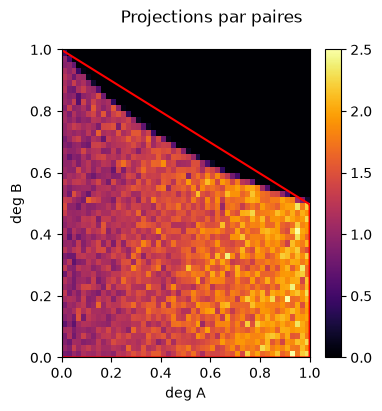

In [26]:
# Heatmap : a -> b
HeatMap(Echantillonage(GraphToMatrix(Args2,AttBasic),100000,1)[1])

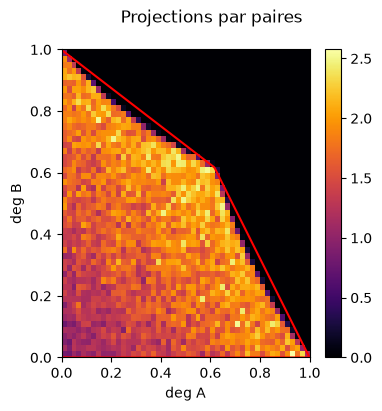

In [27]:
# Heatmap : a <-> b
HeatMap(Echantillonage(GraphToMatrix(Args2,AttRec),100000,1)[1])

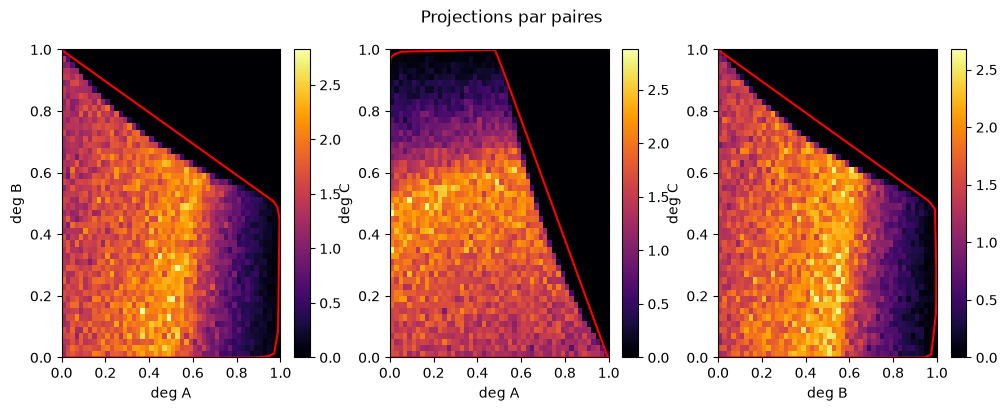

In [28]:
# Heatmap : cycle a -> b -> c -> a
HeatMap(Echantillonage(GraphToMatrix(Args3,AttCycle),100000,1)[1])

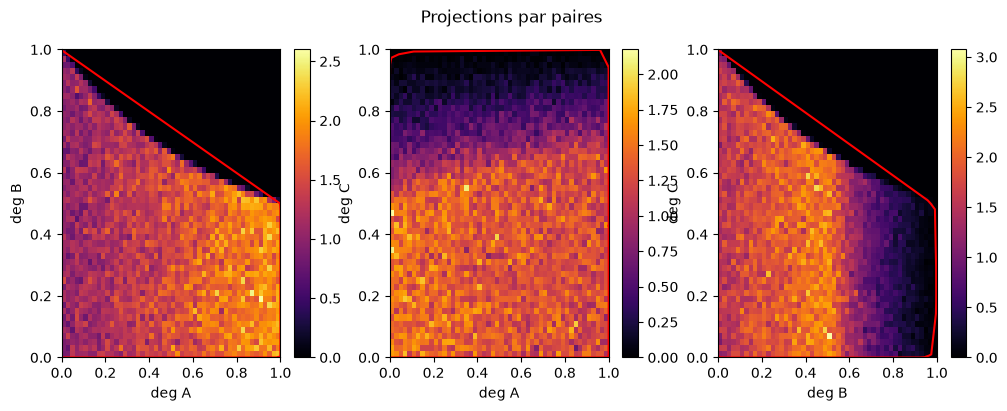

In [29]:
# Heatmap : chaîne
HeatMap(Echantillonage(GraphToMatrix(Args3,AttChaine),100000,1)[1])

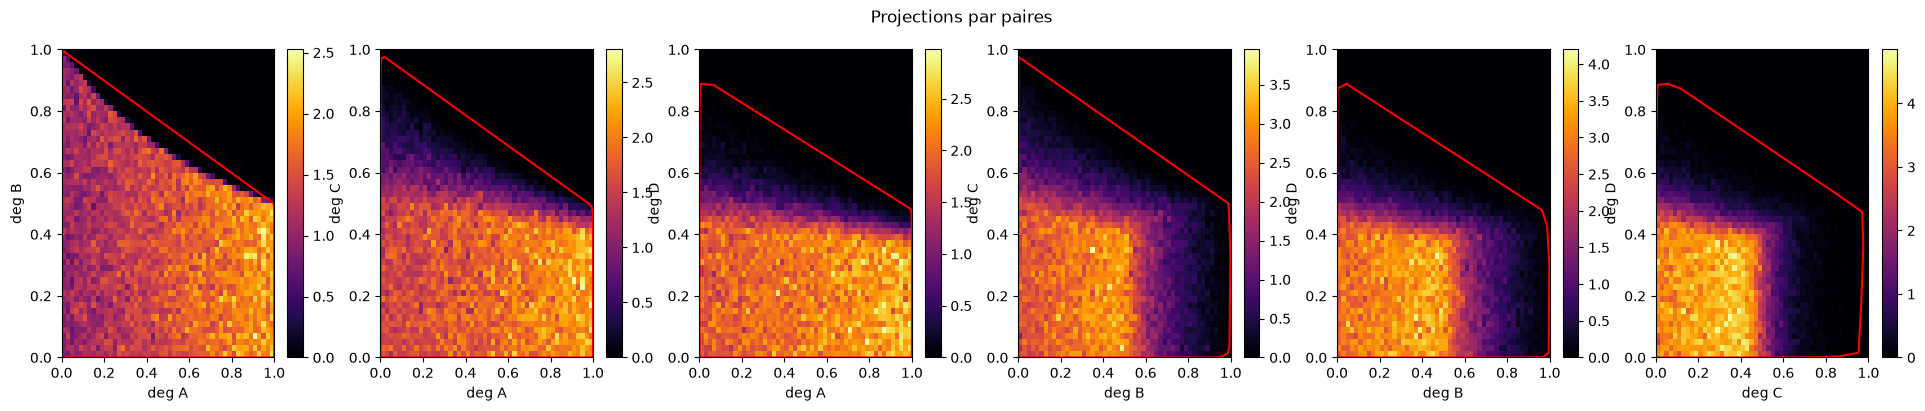

In [30]:
# Heatmap : graphe à 4 arguments
HeatMap(Echantillonage(GraphToMatrix(Args4,Att4),100000,1)[1])

In [31]:
# Statistiques des heatmaps (chiffres cités dans l'analyse)
def StatsHeatmap(X):
  for i, j in itertools.combinations(range(X.shape[1]), 2):
    hist = np.histogram2d(X[:, i], X[:, j], bins=50, range=[[0, 1], [0, 1]], density=True)[0]
    print(f"  paire ({chr(ord('A') + i)}, {chr(ord('A') + j)}) : cases vides = {100 * np.mean(hist == 0):.1f} %, densité max = {hist.max():.2f}")

for nom, Args, Att in [("sans attaque", Args2, AttNone), ("a -> b", Args2, AttBasic), ("a <-> b", Args2, AttRec),
                       ("cycle", Args3, AttCycle), ("chaîne", Args3, AttChaine), ("4 arguments", Args4, Att4)]:
  print(nom)
  StatsHeatmap(Echantillonage(GraphToMatrix(Args, Att), 100000, 1)[1])

sans attaque
  paire (A, B) : cases vides = 0.0 %, densité max = 1.53
a -> b
  paire (A, B) : cases vides = 29.4 %, densité max = 2.50
a <-> b
  paire (A, B) : cases vides = 40.1 %, densité max = 2.57
cycle
  paire (A, B) : cases vides = 29.9 %, densité max = 2.82
  paire (A, C) : cases vides = 29.8 %, densité max = 2.88
  paire (B, C) : cases vides = 30.0 %, densité max = 2.67
chaîne
  paire (A, B) : cases vides = 29.4 %, densité max = 2.60
  paire (A, C) : cases vides = 1.5 %, densité max = 2.18
  paire (B, C) : cases vides = 30.4 %, densité max = 3.07
4 arguments
  paire (A, B) : cases vides = 29.5 %, densité max = 2.52
  paire (A, C) : cases vides = 31.0 %, densité max = 2.80
  paire (A, D) : cases vides = 36.1 %, densité max = 2.97
  paire (B, C) : cases vides = 31.7 %, densité max = 3.95
  paire (B, D) : cases vides = 37.1 %, densité max = 4.20


  paire (C, D) : cases vides = 42.8 %, densité max = 4.85


**Analyse des heatmaps**

Les chiffres cités viennent de la cellule « Statistiques des heatmaps ».

- **Sans attaque** : x = w, donc la densité est uniforme (≈ 1 partout, au bruit près). C'est la référence.
- **Auto-attaque (histogramme 1D)** : x(1 + x) = w, donc x ne dépasse pas 0,618 (cas w = 1). Pour t ≤ 0,618 : P(x ≤ t) = P(w ≤ t + t²) = t + t², d'où une densité de 1 + 2t. L'histogramme suit bien la droite rouge. La dernière barre est plus basse seulement parce que la borne 0,618 coupe cette case.
- **a → b** : x_a est uniforme et, pour x_a fixé, x_b est uniforme entre 0 et 1/(1 + x_a). Donc la densité vaut 1 + x_a : les points sont plus tassés à droite. 29,4 % des cases sont vides (entre la courbe et le haut du carré).
- **a ↔ b** : la densité est faible près de l'origine et plus forte le long de la frontière, surtout vers le coin (0,618 ; 0,618), le point atteint quand w_a = w_b = 1. La frontière est formée de deux arcs de courbe, que l'enveloppe remplace par deux segments.
- **Cycle** : dans chaque projection, la densité est forte pour le premier argument entre 0,4 et 0,6, puis chute vers 1. Pour avoir un degré proche de 1, il faut que son attaquant soit presque nul, ce qui est rare. L'enveloppe couvre cette zone peu dense.
- **Chaîne** : (a, b) reproduit a → b. (b, c) a la même forme, avec peu de points pour b proche de 1. (a, c) n'a pas d'attaque directe, donc presque tout le carré est rempli (1,5 % de cases vides).
- **4 arguments** : plus un argument est attaqué, plus il est écrasé vers 0 et concentré. La densité max passe de 2,52 pour (a, b) à 4,85 pour (c, d), et les cases vides de 29,5 % à 42,8 %.

**Commentaire commun**
- Un w uniforme ne donne pas un x uniforme, sauf sans attaque : la sémantique déforme la distribution.
- L'enveloppe ne dit rien de la densité : elle contient des zones vides ou presque vides, et les zones denses sont souvent collées à la frontière.
- Lien avec la résilience : à 100 000 points la heatmap est stable d'une seed à l'autre, beaucoup moins à 1 000 (cf. ci-dessous). En dimension plus grande, il y a plus de cases à remplir, donc il faudrait encore plus de points.

In [32]:
def TestResilience(M, Nvalues=(1000, 10000, 100000), Seeds=(123, 342, 154, 216, 486)):
  """
  Test de résilience de la heatmap et des enveloppes convexes
  Entrées : M matrice d'adjacence, Nvalues liste des tailles d'échantillons, Seeds liste des graines
  Sorties : None
  """

  for N in Nvalues:
    Heatmaps = []
    Volumes = []

    for seed in Seeds:
      # 1. Échantillonnage
      W, X = Echantillonage(M, N, seed)

      # 2. Calcul de la heatmap
      hist = np.histogram2d(X[:, 0], X[:, 1], bins=50, range=[[0, 1], [0, 1]], density=True)[0]
      Heatmaps.append(hist)

      # 3. Calcul du volume de l'enveloppe convexe
      hull = scipy.spatial.ConvexHull(X[:, [0, 1]])
      Volumes.append(hull.volume)

    # 4. Calcul de la différence moyenne pour les heatmaps
    diffs = []
    for i in range(len(Seeds)):
      for j in range(i + 1, len(Seeds)):
        diff_moyenne = np.mean(np.abs(Heatmaps[i] - Heatmaps[j]))
        diffs.append(diff_moyenne)


    print(f"Pour N = {N} :")
    print(f"Différence moyenne entre heatmaps : {(np.mean(diffs))}")
    print(f"Volumes des enveloppes convexes : {Volumes}")
    print(f"Aire moyenne des enveloppes : {np.mean(Volumes)}")
    print(f"Écarttype des volumes : {np.std(Volumes)}")
    print()

# Exec sur A -> B
MBasic = GraphToMatrix(Args2, AttBasic)
TestResilience(MBasic)

Pour N = 1000 :
Différence moyenne entre heatmaps : 1.2818
Volumes des enveloppes convexes : [0.7240800539162976, 0.7083825582117522, 0.7159747459850282, 0.7147223574933724, 0.6971095666071067]
Aire moyenne des enveloppes : 0.7120538564427114
Écarttype des volumes : 0.008988146947233589

Pour N = 10000 :
Différence moyenne entre heatmaps : 0.46979999999999994
Volumes des enveloppes convexes : [0.743948026814161, 0.7427567949277155, 0.7429811132057456, 0.7435901346607074, 0.7452617940113454]
Aire moyenne des enveloppes : 0.7437075727239348
Écarttype des volumes : 0.0008853175168031742



Pour N = 100000 :


Différence moyenne entre heatmaps : 0.150382
Volumes des enveloppes convexes : [0.7487091589566662, 0.7487988749217985, 0.7475828806233981, 0.7482113043265557, 0.7486327240452232]
Aire moyenne des enveloppes : 0.7483869885747283
Écarttype des volumes : 0.000449729828187707



**Analyse du test de résilience**

Le test porte uniquement sur le graphe a → b (2 arguments) : 5 seeds différentes pour chaque taille d'échantillon N.

*Heatmaps*
- La différence moyenne entre deux heatmaps passe de 1,28 (N = 1 000) à 0,47 (N = 10 000) puis à 0,15 (N = 100 000), soit une division par 2,7 puis par 3,1.
- Le second rapport est proche de √10 ≈ 3,16, ce qu'on attend : l'erreur d'un histogramme diminue en 1/√N.
- Le premier rapport est plus petit. On a 50 × 50 = 2 500 cases pour seulement 1 000 points, donc la plupart des cases contiennent 0 ou 1 point : chaque case est trop peu remplie pour que l'erreur suive déjà la loi en 1/√N. Le résultat dépend donc aussi du nombre de bins choisi.

*Enveloppes*
- Le volume moyen vaut ≈ 0,712, puis 0,744, puis 0,748 : il augmente vers 0,75. Ce 0,75 est l'aire de l'enveloppe théorique (le trapèze de sommets (0, 0), (1, 0), (1, 0,5), (0, 1)), pas l'aire réelle de l'espace, qui vaut ln 2 ≈ 0,693. C'est cohérent avec la sur-approximation d'environ 8 % vue plus haut.
- Le volume reste toujours sous 0,75, car avec un nombre fini de points on n'atteint jamais exactement les coins du trapèze.
- L'écart-type entre seeds passe de 0,009 à 0,0009 puis à 0,0004 : il est divisé par 10 puis par 2.

*Conclusion* : pour a → b, à N = 100 000, la heatmap et l'enveloppe changent très peu d'une seed à l'autre. À N = 1 000, la heatmap est nettement moins fiable, l'enveloppe un peu moins. On n'a pas testé de graphe plus grand : avec plus d'arguments, il faudrait sans doute plus de points pour obtenir la même stabilité.